## Classificando CIFAR-10 com Data Augmentation

Neste exercício, revisitamos o CIFAR-10 e as redes que construímos anteriormente. Usaremos data augmentation (aumento de dados) em tempo real para tentar melhorar nossos resultados.

Quando terminar de passar pelo notebook, experimente diferentes parâmetros de data augmentation e veja se eles ajudam (ou prejudicam!) o desempenho do seu classificador.

In [2]:
from __future__ import print_function
import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Input, RandomFlip, RandomTranslation, RandomRotation, RandomZoom, RandomContrast
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Normalization
import math

import matplotlib.pyplot as plt
%matplotlib inline

tf.keras.utils.set_random_seed(42)

In [3]:
import numpy as np
from datasets import load_dataset

dataset = load_dataset('uoft-cs/cifar10')
#baixando pelo hugging face pq é bem mais rápido

x_train = np.array(dataset['train']['img'])
y_train = np.array(dataset['train']['label'])
x_test = np.array(dataset['test']['img'])
y_test = np.array(dataset['test']['label'])

print('Formato de x_train:', x_train.shape)
print(x_train.shape[0], 'amostras de treino')
print(x_test.shape[0], 'amostras de teste')


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Formato de x_train: (50000, 32, 32, 3)
50000 amostras de treino
10000 amostras de teste


In [4]:
# Os dados, embaralhados e divididos entre conjuntos de treino e teste:
"""
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
print('Formato de x_train:', x_train.shape)
print(x_train.shape[0], 'amostras de treino')
print(x_test.shape[0], 'amostras de teste')
"""

"\n(x_train, y_train), (x_test, y_test) = cifar10.load_data()\nprint('Formato de x_train:', x_train.shape)\nprint(x_train.shape[0], 'amostras de treino')\nprint(x_test.shape[0], 'amostras de teste')\n"

In [5]:
num_classes = 10

y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

In [6]:
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255

No Exercício 6, construímos dois modelos. Um era menor (181K parâmetros) enquanto o segundo era maior (1.25M parâmetros). Abaixo, usamos o modelo menor e o treinamos com data augmentation.

In [ ]:
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomTranslation(height_factor=0.1, width_factor=0.1),
    RandomRotation(factor=0.05),
])

import keras
from keras.callbacks import EarlyStopping


early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
# Vamos construir uma CNN usando as capacidades Sequential do Keras

model_1 = Sequential()

model_1.add(Input(shape=x_train[0].shape))
model_1.add(data_augmentation)
## Convolução 5x5 com stride 2x2 e 32 filtros
model_1.add(Conv2D(32, (5, 5), strides = (2,2), padding='same'))
model_1.add(Activation('relu'))

## Outra convolução 5x5 com stride 2x2 e 32 filtros
model_1.add(Conv2D(32, (5, 5), strides = (2,2)))
model_1.add(Activation('relu'))

## Max pooling 2x2 reduz para 3 x 3 x 32
model_1.add(MaxPooling2D(pool_size=(2, 2)))
model_1.add(Dropout(0.25))

## Flatten transforma 3x3x32 em 288x1
model_1.add(Flatten())
model_1.add(Dense(512))
model_1.add(Activation('relu'))
model_1.add(Dropout(0.5))
model_1.add(Dense(num_classes))
model_1.add(Activation('softmax'))

model_1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 6, 6, 32)       │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       147,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 181,162 (707.66 KB)

 Trainable params: 181,162 (707.66 KB)

 Non-trainable params: 0 (0.00 B)

Ainda temos 181K parâmetros, mesmo que este seja um modelo "pequeno".

In [ ]:
batch_size = 32

# Inicializar otimizador RMSprop
opt = keras.optimizers.RMSprop(learning_rate=0.0001, decay=1e-6)

# Vamos treinar o modelo usando RMSprop
model_1.compile(loss='categorical_crossentropy',
              optimizer=opt,
              metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


Aqui definimos o `ImageDataGenerator` que usaremos para servir imagens ao nosso modelo durante o processo de treinamento. Atualmente, ele está configurado para fazer alguns deslocamentos e inversão horizontal.

In [ ]:
datagen = ImageDataGenerator(
    featurewise_center=False,  # definir média de entrada para 0 sobre o conjunto de dados
    samplewise_center=False,  # definir cada média de amostra para 0
    featurewise_std_normalization=False,  # dividir entradas pelo desvio padrão do conjunto de dados
    samplewise_std_normalization=False,  # dividir cada entrada pelo seu desvio padrão
    zca_whitening=False,  # aplicar whitening ZCA
    rotation_range=0,  # girar aleatoriamente imagens no intervalo (graus, 0 a 180)
    width_shift_range=0.1,  # deslocar aleatoriamente imagens horizontalmente (fração da largura total)
    height_shift_range=0.1,  # deslocar aleatoriamente imagens verticalmente (fração da altura total)
    horizontal_flip=True,  # inverter aleatoriamente imagens horizontalmente
    vertical_flip=False)  # inverter aleatoriamente imagens verticalmente

datagen.fit(x_train)      # Isso calcula quaisquer estatísticas que possam ser necessárias (por exemplo, para centralização) a partir do conjunto de treinamento.

#ainda vou deixar isso aqui, mas vou aplicar o data augmentation direto no sequential, a divisão dos batchs ta deixando algumas épocas
#com pouquissimas imagens e rodando em menos de 1s, desperdiçando épocas. isso é sobre a iteração do datagen.flow


# Ajustar o modelo nos lotes gerados por datagen.flow().
history1 = model_1.fit(x_train, y_train,
                      batch_size=batch_size,
                      epochs=20,
                      validation_data=(x_test, y_test))

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 7ms/step - accuracy: 0.2547 - loss: 2.0038 - val_accuracy: 0.3946 - val_loss: 1.7226
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.3684 - loss: 1.7287 - val_accuracy: 0.4412 - val_loss: 1.5561
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4059 - loss: 1.6297 - val_accuracy: 0.4608 - val_loss: 1.4920
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4282 - loss: 1.5750 - val_accuracy: 0.4826 - val_loss: 1.4425
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4461 - loss: 1.5306 - val_accuracy: 0.4942 - val_loss: 1.3976
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4597 - loss: 1.4960 - val_accuracy: 0.5090 - val_loss: 1.3650
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.4721 - loss: 1.4660 - val_accuracy: 0.5243 - val_loss: 1.3319
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4808 - loss: 1

Como o desempenho se compara com o treinamento sem augmentation?

In [ ]:
loss, accuracy = model_1.evaluate(x=x_test, y=y_test, batch_size=32, verbose=1)

print(f'Loss: {loss:.3f}')
print(f'Acurácia: {accuracy:.3f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5923 - loss: 1.1447
Loss: 1.145
Acurácia: 0.592


não tem uma atividade anterior que usa esse mesmo modelo sem data augmentation, então vou treinar denovo sem, pra comparar o desempenho.


In [ ]:
model_2 = Sequential()

model_2.add(Input(shape=x_train.shape[1:]))
model_2.add(data_augmentation)
model_2.add(Conv2D(32, (5, 5), strides = (2,2), padding='same',))
model_2.add(Activation('relu'))
model_2.add(Conv2D(32, (5, 5), strides = (2,2)))
model_2.add(Activation('relu'))
model_2.add(MaxPooling2D(pool_size=(2, 2)))
model_2.add(Dropout(0.25))
model_2.add(Flatten())
model_2.add(Dense(512))
model_2.add(Activation('relu'))
model_2.add(Dropout(0.5))
model_2.add(Dense(num_classes))
model_2.add(Activation('softmax'))

opt2 = keras.optimizers.RMSprop(learning_rate=0.0001, decay=1e-6)

model_2.compile(optimizer=opt2, metrics=['accuracy'],
                loss='categorical_crossentropy')

model_2.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 32)       │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       147,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 181,162 (707.66 KB)

 Trainable params: 181,162 (707.66 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history2 = model_2.fit(x_train, y_train, batch_size, epochs=18, validation_data=(x_test, y_test),)

Epoch 1/18
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.2583 - loss: 2.0093 - val_accuracy: 0.3705 - val_loss: 1.7575
Epoch 2/18
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.3673 - loss: 1.7403 - val_accuracy: 0.4364 - val_loss: 1.5775
Epoch 3/18
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4041 - loss: 1.6289 - val_accuracy: 0.4592 - val_loss: 1.5026
Epoch 4/18
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4304 - loss: 1.5663 - val_accuracy: 0.4752 - val_loss: 1.4531
Epoch 5/18
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4494 - loss: 1.5212 - val_accuracy: 0.4990 - val_loss: 1.3983
Epoch 6/18
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4607 - loss: 1.4853 - val_accuracy: 0.5089 - val_loss: 1.3649
Epoch 7/18
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4726 - loss: 1.4555 - val_accuracy: 0.5179 - val_loss: 1.3491
Epoch 8/18
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4851 - loss: 1

In [ ]:
loss2, accuracy2 = model_2.evaluate(x_test, y_test, batch_size=32, verbose=1)

print(f'Loss: {loss2:.3f}')
print(f'Acurácia: {accuracy2:.3f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5939 - loss: 1.1342
Loss: 1.134
Acurácia: 0.594


vamos ver a diferença com gráficos

In [7]:
def plot_loss_accuracy(history):

    global x_test
    global y_test

    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(1, 2, 1)
    ax.plot(history.history["loss"],'r-x', marker='.', label="Perda de Treino")
    ax.plot(history.history["val_loss"],'b-x', marker='.', label="Perda de Validação")
    ax.legend()
    ax.set_title('perda cross_entropy')
    ax.grid(True)


    ax = fig.add_subplot(1, 2, 2)
    ax.plot(history.history["accuracy"],'r', marker='.', label="Precisão de Treino")
    ax.plot(history.history["val_accuracy"],'b', marker='.', label="Precisão de Validação")
    ax.legend()
    ax.set_title('precisão')
    ax.grid(True)

COM DATA AUGMENTATION


/tmp/ipykernel_4586/589865735.py:8: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "r-x" (-> marker='x'). The keyword argument will take precedence.
  ax.plot(history.history["loss"],'r-x', marker='.', label="Perda de Treino")
/tmp/ipykernel_4586/589865735.py:9: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "b-x" (-> marker='x'). The keyword argument will take precedence.
  ax.plot(history.history["val_loss"],'b-x', marker='.', label="Perda de Validação")


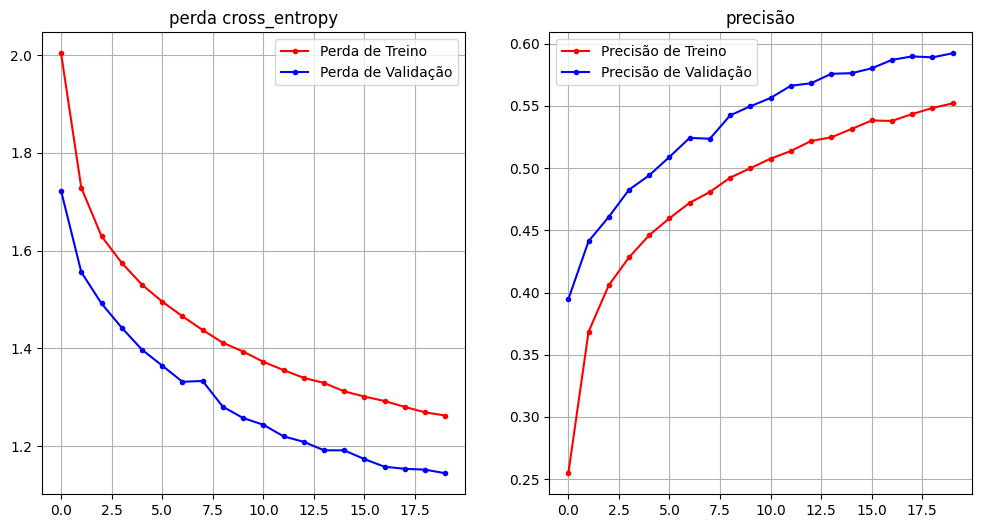

In [ ]:
print(f'COM DATA AUGMENTATION')
plot_loss_accuracy(history1)

SEM DATA AUGMENTATION


/tmp/ipykernel_4586/589865735.py:8: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "r-x" (-> marker='x'). The keyword argument will take precedence.
  ax.plot(history.history["loss"],'r-x', marker='.', label="Perda de Treino")
/tmp/ipykernel_4586/589865735.py:9: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "b-x" (-> marker='x'). The keyword argument will take precedence.
  ax.plot(history.history["val_loss"],'b-x', marker='.', label="Perda de Validação")


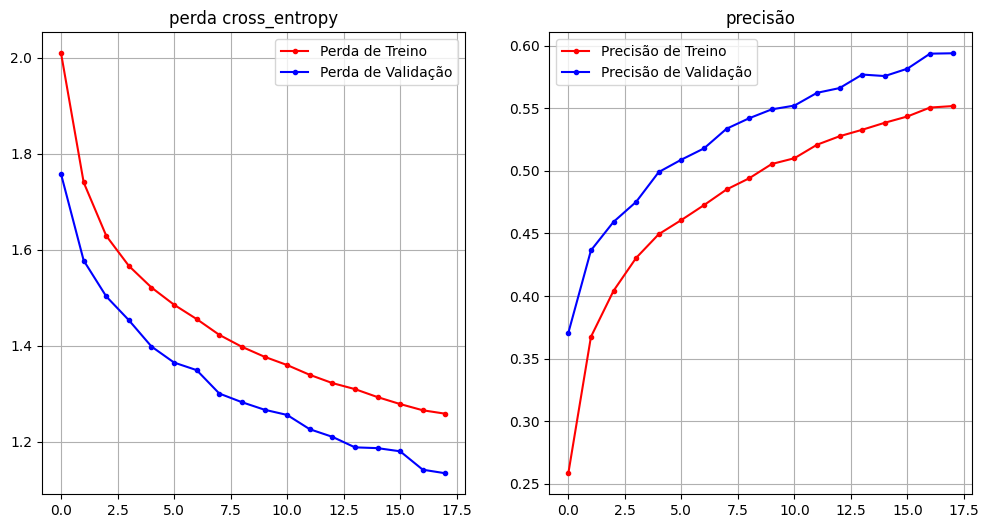

In [ ]:
print('SEM DATA AUGMENTATION')
plot_loss_accuracy(history2)

In [ ]:
score1 = model_1.evaluate(x_test, y_test, batch_size=32, verbose=0)
score2 = model_2.evaluate(x_test, y_test, batch_size=32, verbose=0)

print(f'DATA AUGMENTATION: Perda no Teste: {score1[0]}, Acurácia no Teste: {score1[1]}')
print(f'SEM DATA AUGMENTATION: Perda no Teste: {score2[0]}, Acurácia no Teste: {score2[1]}')

DATA AUGMENTATION: Perda no Teste: 1.1447497606277466, Acurácia no Teste: 0.5922999978065491
SEM DATA AUGMENTATION: Perda no Teste: 1.1342190504074097, Acurácia no Teste: 0.5939000248908997


o sem data augmentation se saiu melhor, porém, vale ressaltar que a data augmentation dificulta o treinamento, fazendo com que sejam necessárias mais épocas para o modelo atingir desempenho. pelas curvas, ainda pode ter mais épocas. Claro, há vários outros fatores que podem influenciar no desempenho da cnn, mas como a atividade já dá um, me baseei nele e vou manter assim.

vou deixar o 1. do exercício aqui. vou testar os parâmetros e deixar os resultados aqui. eu coloquei sobre o uso do datagen e ele tá prejudicando o treinamento, então vou por as configurações no sequential aqui.


# Testes

1.   
**DATA AUGMENTATION:** Perda no Teste: 1.238136887550354, Acurácia no Teste: 0.5902000069618225
**SEM DATA AUGMENTATION:** Perda no Teste: 1.1346439123153687, Acurácia no Teste: 0.6015999913215637

já tem descrição em cima

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomTranslation(height_factor=0.1, width_factor=0.1),
    RandomRotation(factor=0.05),
])


2.

não foi um ajuste no data augmentation, mas só aumentei as épocas pra 17 pra ver o resultado. o com data augmentation tá muito ruidoso, o sem também, mas menos. tendo em vista que o modelo com data augmentation ainda está ruim.

DATA AUGMENTATION: Perda no Teste: 1.339587688446045, Acurácia no Teste: 0.5504000186920166
SEM DATA AUGMENTATION: Perda no Teste: 1.0977706909179688, Acurácia no Teste: 0.6211000084877014



3.   

Último ajuste antes de começar a mexer na data augmentation. vou por um lr maior para ver o que acontece, suspeito de underfitting no modelo com data augmentation. vou por 20 épocas pra ver bem se as métricas de treino estão se estabilizando, pra saber como estão as métricas de validação ao final do treino.

DATA AUGMENTATION: Perda no Teste: 1.4885565042495728, Acurácia no Teste: 0.5016999840736389
SEM DATA AUGMENTATION: Perda no Teste: 1.328788161277771, Acurácia no Teste: 0.5461000204086304

é, só piorou o modelo, de várias maneiras. vou tirar essa lr e deixar as 20 épocas, talvez a capacidade da rede neural e arquitetura sejam uma limitação

4.   

coloquei lr menor, o com data augmentation convergiu bem melhor, e, pelo gráfico, precisa de mais épocas, pois as métricas progridem de forma consistente.

5.    

Agora pra começar a testar a data augmentation. vou deixar como estava no passo anterior, não vou mudar o otimizador pra manter o exercício. Reduzi os parâmetros pela metade e os modelos ficaram semelhantes. faz sentido. Não vejo o que mudar na data augmentation, só precisa de mais épocas. Não vou mexer mais, tem outras questões pra fazer. Aumentar parâmetros ou adicionar camadas só vai aumentar a necessidade de camadas.








## Exercício
### Sua Vez

1. Experimente acima com diferentes configurações dos parâmetros de data augmentation. Você consegue fazer o modelo ter um desempenho melhor? Você consegue fazer ele ter um desempenho pior?

2. Como no Exercício 4b, construa um modelo mais complicado com o seguinte padrão:
    - Conv -> Conv -> MaxPool -> Conv -> Conv -> MaxPool -> (Flatten) -> Dense -> Classificação Final
    - Use strides de 1 para todas as camadas convolucionais.

3. Use data augmentation para treinar este modelo. Você consegue obter um desempenho melhor?

In [25]:
# Vamos construir uma CNN usando as capacidades Sequential do Keras

model_3 = Sequential()

data_augmentation2 = Sequential([
    RandomFlip('horizontal'),
    RandomRotation(0.15),
    RandomZoom(0.1),
    RandomTranslation(height_factor=0.1, width_factor=0.1),
    #RandomContrast(0.2) só piorou
])

norm = Normalization()
norm.adapt(x_train)

model_3.add(Input(shape=x_train.shape[1:]))
model_3.add(norm)
model_3.add(data_augmentation2)
model_3.add(Conv2D(16, (3, 3), strides=(1, 1), activation='gelu', padding='same'))
model_3.add(Conv2D(32, (3, 3), strides=(1, 1), activation='gelu', padding='same'))
model_3.add(MaxPooling2D(pool_size=(2, 2)))
model_3.add(Conv2D(64, (3, 3), strides=(1, 1), activation='gelu', padding='same'))
model_3.add(Conv2D(128, (3, 3), strides=(1, 1), activation='gelu', padding='same'))
model_3.add(MaxPooling2D(pool_size=(2, 2)))
model_3.add(Flatten())
model_3.add(Dense(512, activation='gelu'))
model_3.add(Dense(num_classes, activation='softmax'))


# Por favor, forneça seu código aqui

In [26]:
## Verificar número de parâmetros (imprimir o summary)

model_3.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_5 (Normalization) │ (None, 32, 32, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_11 (Sequential)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,297,393 (16.39 MB)

 Trainable params: 4,297,386 (16.39 MB)

 Non-trainable params: 7 (32.00 B)

In [27]:
from keras.optimizers import RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
# Inicializar otimizador RMSprop

optmizer = RMSprop(0.0001)

early_stop = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

reduce_lr = ReduceLROnPlateau(monitor="val_loss",factor=0.3,patience=4,min_lr=1e-6)

model_3.compile(loss='categorical_crossentropy', metrics=["accuracy"], optimizer=optmizer)

history3 = model_3.fit(x_train, y_train, batch_size=32, epochs=40, validation_data=(x_test, y_test), callbacks=[early_stop, reduce_lr])

# Vamos treinar o modelo usando RMSprop

Epoch 1/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.3709 - loss: 1.7599 - val_accuracy: 0.4421 - val_loss: 1.5890 - learning_rate: 1.0000e-04
Epoch 2/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.4547 - loss: 1.5273 - val_accuracy: 0.4758 - val_loss: 1.4926 - learning_rate: 1.0000e-04
Epoch 3/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.4934 - loss: 1.4180 - val_accuracy: 0.5038 - val_loss: 1.4213 - learning_rate: 1.0000e-04
Epoch 4/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.5200 - loss: 1.3467 - val_accuracy: 0.5303 - val_loss: 1.3665 - learning_rate: 1.0000e-04
Epoch 5/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.5455 - loss: 1.2798 - val_accuracy: 0.5474 - val_loss: 1.3248 - learning_rate: 1.0000e-04
Epoch 6/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.5693 - loss: 1.2226 - val_accuracy: 0.5629 - val_loss: 1.2930 - learning_rate: 1.0000e-04
Epoch 7/40
1563/1563 ━━━━━━━━━━━━━━━━━━━

/tmp/ipykernel_492/589865735.py:8: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "r-x" (-> marker='x'). The keyword argument will take precedence.
  ax.plot(history.history["loss"],'r-x', marker='.', label="Perda de Treino")
/tmp/ipykernel_492/589865735.py:9: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "b-x" (-> marker='x'). The keyword argument will take precedence.
  ax.plot(history.history["val_loss"],'b-x', marker='.', label="Perda de Validação")


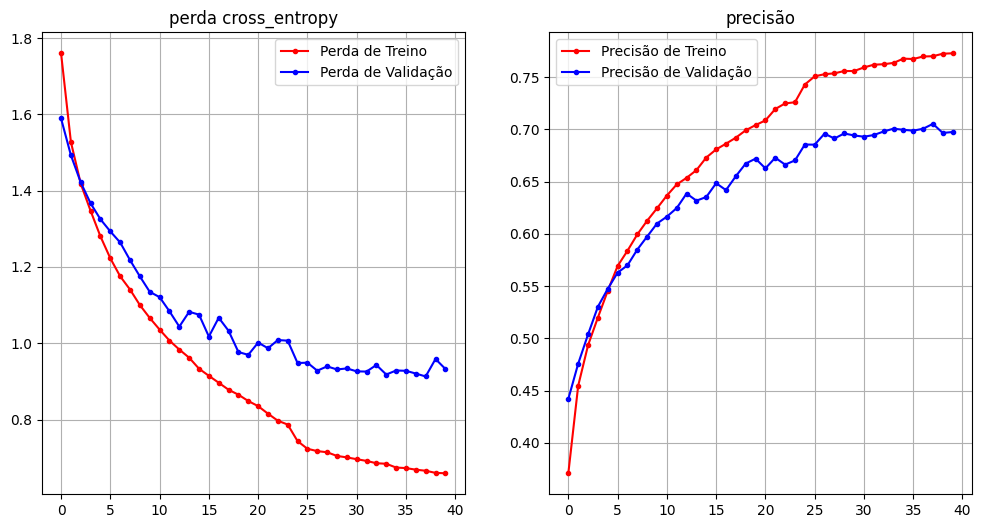

In [30]:
plot_loss_accuracy(history3)

In [31]:
"""vimos sobre alguns outros métodos em treinamentos de cnns. quero por mais épocas,
com earlystop e reducelronplateu. quero ver o potencial dessa cnn"""

'vimos sobre alguns outros métodos em treinamentos de cnns. quero por mais épocas,\ncom earlystop e reducelronplateu. quero ver o potencial dessa cnn'

In [32]:
# Calcular quantidades necessárias para normalização por feature


# Ajustar o modelo nos lotes gerados por datagen.flow().


"""como nao to usando datagen, vou so colocar norm.
o modelo ta com overfitting, teria como evitar isso com
dropout, batchnormalization, outros otimizadores e outros
regularizadores como l2. mas o exercício pede uma arquitetura
específica. mais épocas vai aumentar o overffiting e mais
camadas de augmentation só piorou."""

'como nao to usando datagen, vou so colocar norm.\no modelo ta com overfitting, teria como evitar isso com \ndropout, batchnormalization, outros otimizadores e outros\nregularizadores como l2. mas o exercício pede uma arquitetura\nespecífica. mais épocas vai aumentar o overffiting e mais \ncamadas de augmentation só piorou.'